# Phase 2: Exploratory Data Analysis (EDA) — RDD2022

**Goal:** Understand the dataset before training — class distribution, bounding box characteristics, background-only rate, and visual samples.

**Dataset used:** Japan (primary country — see `data_strategy.md` for rationale)

**Key questions to answer:**
1. How imbalanced are the 4 classes after filtering unknown labels?
2. What do bounding boxes look like per class (size, shape, location)?
3. How many background-only images are there per country?
4. What do the actual damage images look like?

**Outputs saved to:** `outputs/figures/` and `outputs/phase2_eda_summary.txt`

In [1]:
# Imports & Setup
import os
import xml.etree.ElementTree as ET
from pathlib import Path
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import seaborn as sns
from PIL import Image

# Plot style
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.family'] = 'DejaVu Sans'
sns.set_theme(style='whitegrid')

print('All libraries loaded successfully.')

All libraries loaded successfully.


In [2]:
# Configuration — paths, class definitions

# Import paths from config/paths.py (project root is one level above notebooks/)
import sys
from pathlib import Path
_proj = Path().resolve()
if not (_proj / 'config').exists():
    _proj = _proj.parent
sys.path.insert(0, str(_proj))
from config.paths import DATA_RAW, OUTPUT_DIR, FIGURES_DIR

# Aliases used throughout this notebook
DATA_DIR = DATA_RAW

os.makedirs(FIGURES_DIR, exist_ok=True)

# 4 valid classes only (per official RDD2022 task definition)
EXPECTED_CLASSES = {'D00', 'D10', 'D20', 'D40'}

CLASS_NAMES = {
    'D00': 'Longitudinal Crack',
    'D10': 'Transverse Crack',
    'D20': 'Alligator Crack',
    'D40': 'Pothole'
}

CLASS_COLORS = {
    'D00': '#E74C3C',
    'D10': '#3498DB',
    'D20': '#2ECC71',
    'D40': '#F39C12'
}

# Countries to include in multi-country comparison
# China_Drone and China_MotorBike excluded — see data_strategy.md
COUNTRIES_VALID = ['Japan', 'India', 'Norway', 'United_States', 'Czech']

print(f'Data dir    : {DATA_DIR}')
print(f'Figures dir : {FIGURES_DIR}')
print(f'Valid classes: {sorted(EXPECTED_CLASSES)}')

Data dir    : /mnt/c/Users/SN23341J001185/Documents/MyWork/ICT/ICTYear3_2/dl/DeepLearningPJ/data/raw/RDD2022
Figures dir : /mnt/c/Users/SN23341J001185/Documents/MyWork/ICT/ICTYear3_2/dl/DeepLearningPJ/outputs/figures
Valid classes: ['D00', 'D10', 'D20', 'D40']


In [3]:
# Helper: parse all annotations into a DataFrame

def parse_all_annotations(country, data_dir, split='train', filter_unknown=True):
    """
    Parse all Pascal VOC XML files for one country/split.
    Returns a DataFrame: one row per bounding box object.
    Background-only images (no valid objects) are kept as BACKGROUND rows.

    Columns: image_id, country, label, class_name,
             xmin, ymin, xmax, ymax, bbox_w, bbox_h, bbox_area,
             img_w, img_h, rel_w, rel_h
    """
    xml_dir = Path(data_dir) / country / split / 'annotations' / 'xmls'

    if not xml_dir.exists():
        print(f'  [SKIP] {country}/{split} — no XML directory found')
        return pd.DataFrame()

    records = []
    xml_files = list(xml_dir.glob('*.xml'))

    for xml_path in xml_files:
        try:
            tree = ET.parse(xml_path)
            root = tree.getroot()
        except ET.ParseError:
            continue

        image_id = xml_path.stem

        # Image dimensions from XML
        size_el = root.find('size')
        img_w = int(size_el.find('width').text)  if size_el is not None else 0
        img_h = int(size_el.find('height').text) if size_el is not None else 0

        valid_objects = []
        for obj in root.findall('object'):
            name_el = obj.find('name')
            bndbox  = obj.find('bndbox')
            if name_el is None or bndbox is None:
                continue

            label = name_el.text.strip()

            # Skip unknown labels when filter_unknown=True
            if filter_unknown and label not in EXPECTED_CLASSES:
                continue

            try:
                xmin = float(bndbox.find('xmin').text)
                ymin = float(bndbox.find('ymin').text)
                xmax = float(bndbox.find('xmax').text)
                ymax = float(bndbox.find('ymax').text)
            except (TypeError, AttributeError):
                continue

            bbox_w = xmax - xmin
            bbox_h = ymax - ymin

            # Skip degenerate bboxes (w or h <= 0)
            if bbox_w <= 0 or bbox_h <= 0:
                continue

            valid_objects.append({
                'image_id':  image_id,
                'country':   country,
                'label':     label,
                'class_name': CLASS_NAMES.get(label, label),
                'xmin': xmin, 'ymin': ymin,
                'xmax': xmax, 'ymax': ymax,
                'bbox_w':    bbox_w,
                'bbox_h':    bbox_h,
                'bbox_area': bbox_w * bbox_h,
                'img_w':     img_w,
                'img_h':     img_h,
                'rel_w':     bbox_w / img_w if img_w > 0 else 0,
                'rel_h':     bbox_h / img_h if img_h > 0 else 0,
            })

        if valid_objects:
            records.extend(valid_objects)
        else:
            # Keep as background row so we can count background-only images
            records.append({
                'image_id': image_id, 'country': country,
                'label': 'BACKGROUND', 'class_name': 'Background',
                'xmin': None, 'ymin': None, 'xmax': None, 'ymax': None,
                'bbox_w': None, 'bbox_h': None, 'bbox_area': None,
                'img_w': img_w, 'img_h': img_h,
                'rel_w': None, 'rel_h': None,
            })

    return pd.DataFrame(records)


# Load Japan training data
print('Loading Japan train annotations (filtering unknown labels)...')
df_japan      = parse_all_annotations('Japan', DATA_DIR, split='train', filter_unknown=True)
df_japan_objs = df_japan[df_japan['label'] != 'BACKGROUND'].copy()
df_japan_bg   = df_japan[df_japan['label'] == 'BACKGROUND'].copy()

print(f'\n--- Japan Train (after filtering unknowns) ---')
print(f'Total images parsed       : {df_japan["image_id"].nunique():,}')
print(f'Images with objects       : {df_japan_objs["image_id"].nunique():,}')
print(f'Background-only images    : {len(df_japan_bg):,}')
print(f'Total valid objects       : {len(df_japan_objs):,}')
print(f'\nClass breakdown:')
for cls in ['D00', 'D10', 'D20', 'D40']:
    n = (df_japan_objs['label'] == cls).sum()
    pct = n / len(df_japan_objs) * 100
    print(f'  {cls} ({CLASS_NAMES[cls]:<20}): {n:>5,}  ({pct:.1f}%)')

Loading Japan train annotations (filtering unknown labels)...

--- Japan Train (after filtering unknowns) ---
Total images parsed       : 10,506
Images with objects       : 7,900
Background-only images    : 2,606
Total valid objects       : 16,469

Class breakdown:
  D00 (Longitudinal Crack  ): 4,049  (24.6%)
  D10 (Transverse Crack    ): 3,979  (24.2%)
  D20 (Alligator Crack     ): 6,198  (37.6%)
  D40 (Pothole             ): 2,243  (13.6%)


/tmp/ipykernel_16706/2882372413.py:22: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(labels)


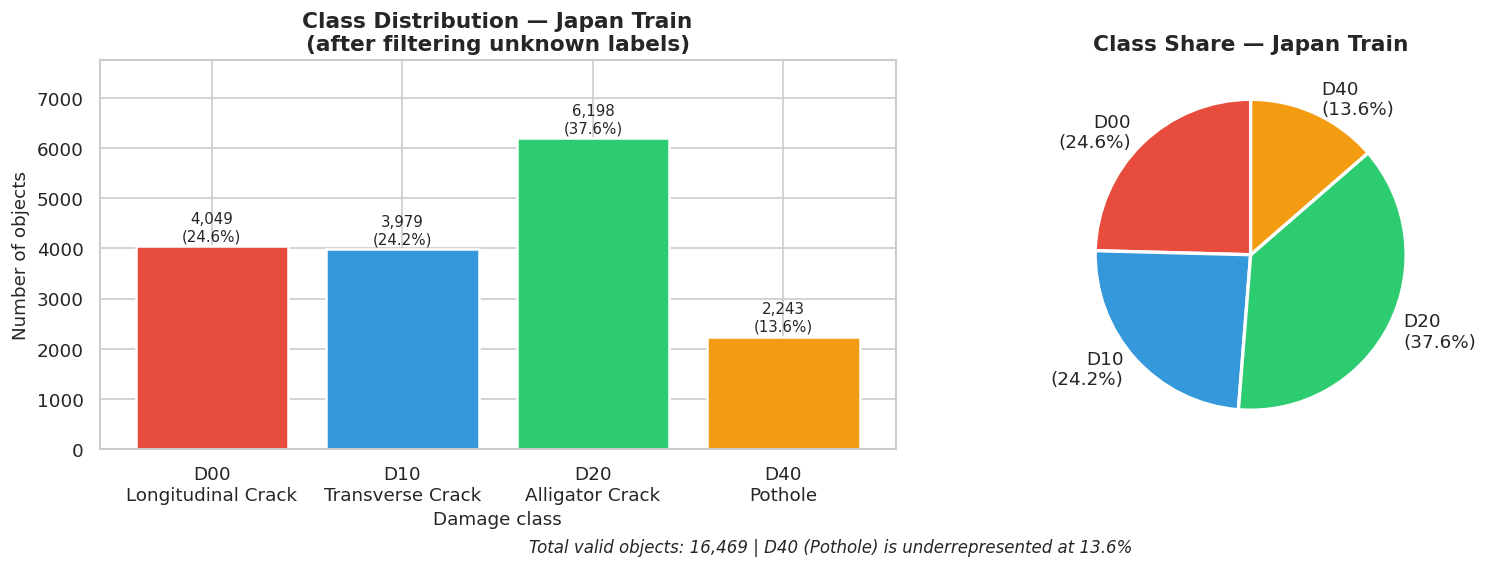

Saved: /mnt/c/Users/SN23341J001185/Documents/MyWork/ICT/ICTYear3_2/dl/DeepLearningPJ/outputs/figures/phase2_class_distribution_japan.png


In [4]:
# Fig 1: Class distribution — Japan train (after filtering)
# Purpose: visualize class imbalance to justify mitigation strategies in training

class_counts = {cls: (df_japan_objs['label'] == cls).sum()
                for cls in ['D00', 'D10', 'D20', 'D40']}
total = sum(class_counts.values())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Bar chart
labels = [f'{k}\n{CLASS_NAMES[k]}' for k in class_counts]
counts = list(class_counts.values())
colors = [CLASS_COLORS[k] for k in class_counts]
bars = axes[0].bar(labels, counts, color=colors, edgecolor='white', linewidth=1.5)
axes[0].set_title('Class Distribution — Japan Train\n(after filtering unknown labels)', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Number of objects', fontsize=11)
axes[0].set_xlabel('Damage class', fontsize=11)
for bar, cnt in zip(bars, counts):
    axes[0].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 50,
                 f'{cnt:,}\n({cnt/total*100:.1f}%)', ha='center', va='bottom', fontsize=9)
axes[0].set_ylim(0, max(counts) * 1.25)
axes[0].set_xticklabels(labels)

# Pie chart
axes[1].pie(counts, labels=[f'{k}\n({v/total*100:.1f}%)' for k, v in class_counts.items()],
            colors=colors, autopct='', startangle=90,
            wedgeprops={'edgecolor': 'white', 'linewidth': 2})
axes[1].set_title('Class Share — Japan Train', fontsize=13, fontweight='bold')

plt.suptitle(f'Total valid objects: {total:,} | D40 (Pothole) is underrepresented at 13.6%',
             fontsize=10, style='italic', y=0.02)
plt.tight_layout()
out_path = FIGURES_DIR / 'phase2_class_distribution_japan.png'
plt.savefig(out_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved: {out_path}')

Loading multi-country annotations (Japan already loaded)...
  Japan: 16,469 valid objects
  India: 6,831 valid objects
  Norway: 11,229 valid objects
  United_States: 11,014 valid objects
  Czech: 1,745 valid objects

                 D00   D10   D20   D40  Total
Country                                     
Japan          4049  3979  6198  2243  16469
India          1555    68  2021  3187   6831
Norway         8570  1730   468   461  11229
United_States  6750  3295   834   135  11014
Czech           988   399   161   197   1745


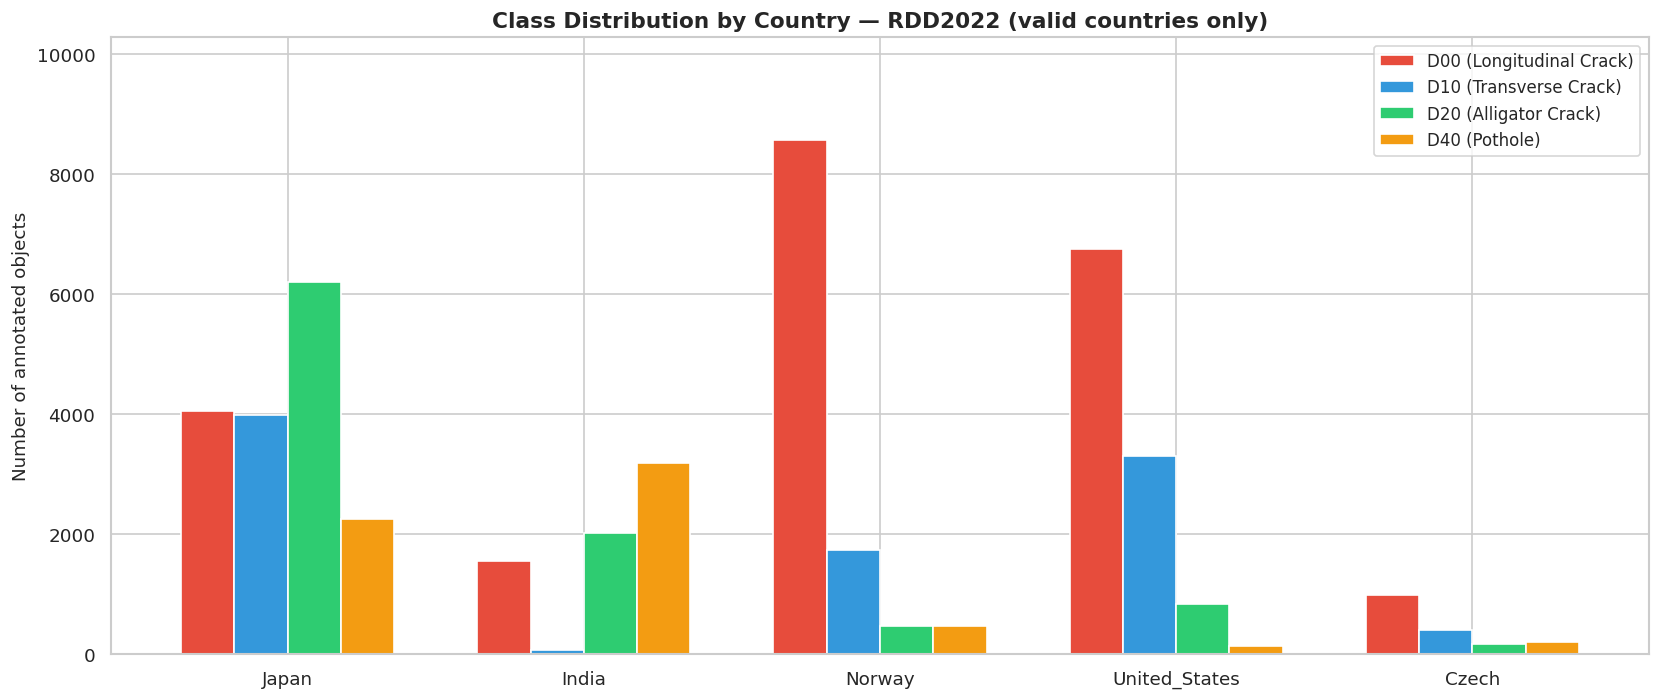

Saved: /mnt/c/Users/SN23341J001185/Documents/MyWork/ICT/ICTYear3_2/dl/DeepLearningPJ/outputs/figures/phase2_class_distribution_by_country.png


In [6]:
# Fig 2: Class distribution across all valid countries
# Purpose: decide which countries to add if a class is underrepresented in Japan

print('Loading multi-country annotations (Japan already loaded)...')
country_dfs = {}
for country in COUNTRIES_VALID:
    df = parse_all_annotations(country, DATA_DIR, split='train', filter_unknown=True)
    if df.empty:
        continue
    country_dfs[country] = df[df['label'] != 'BACKGROUND'].copy()
    print(f'  {country}: {len(country_dfs[country]):,} valid objects')

# Build summary table: rows=country, cols=class
summary_rows = []
for country, df in country_dfs.items():
    row = {'Country': country}
    for cls in ['D00', 'D10', 'D20', 'D40']:
        row[cls] = (df['label'] == cls).sum()
    row['Total'] = sum(row[cls] for cls in ['D00', 'D10', 'D20', 'D40'])
    summary_rows.append(row)
df_summary = pd.DataFrame(summary_rows).set_index('Country')
print('\n', df_summary)

# Grouped bar chart
x = np.arange(len(df_summary))
width = 0.18
fig, ax = plt.subplots(figsize=(14, 6))
for i, cls in enumerate(['D00', 'D10', 'D20', 'D40']):
    ax.bar(x + i * width, df_summary[cls], width, label=f'{cls} ({CLASS_NAMES[cls]})',
           color=CLASS_COLORS[cls], edgecolor='white')
ax.set_xticks(x + width * 1.5)
ax.set_xticklabels(df_summary.index, fontsize=11)
ax.set_ylabel('Number of annotated objects', fontsize=11)
ax.set_title('Class Distribution by Country — RDD2022 (valid countries only)', fontsize=13, fontweight='bold')
ax.legend(fontsize=10, loc='upper right')
ax.set_ylim(0, df_summary[['D00','D10','D20','D40']].values.max() * 1.2)
plt.tight_layout()
out_path = FIGURES_DIR / 'phase2_class_distribution_by_country.png'
plt.savefig(out_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved: {out_path}')

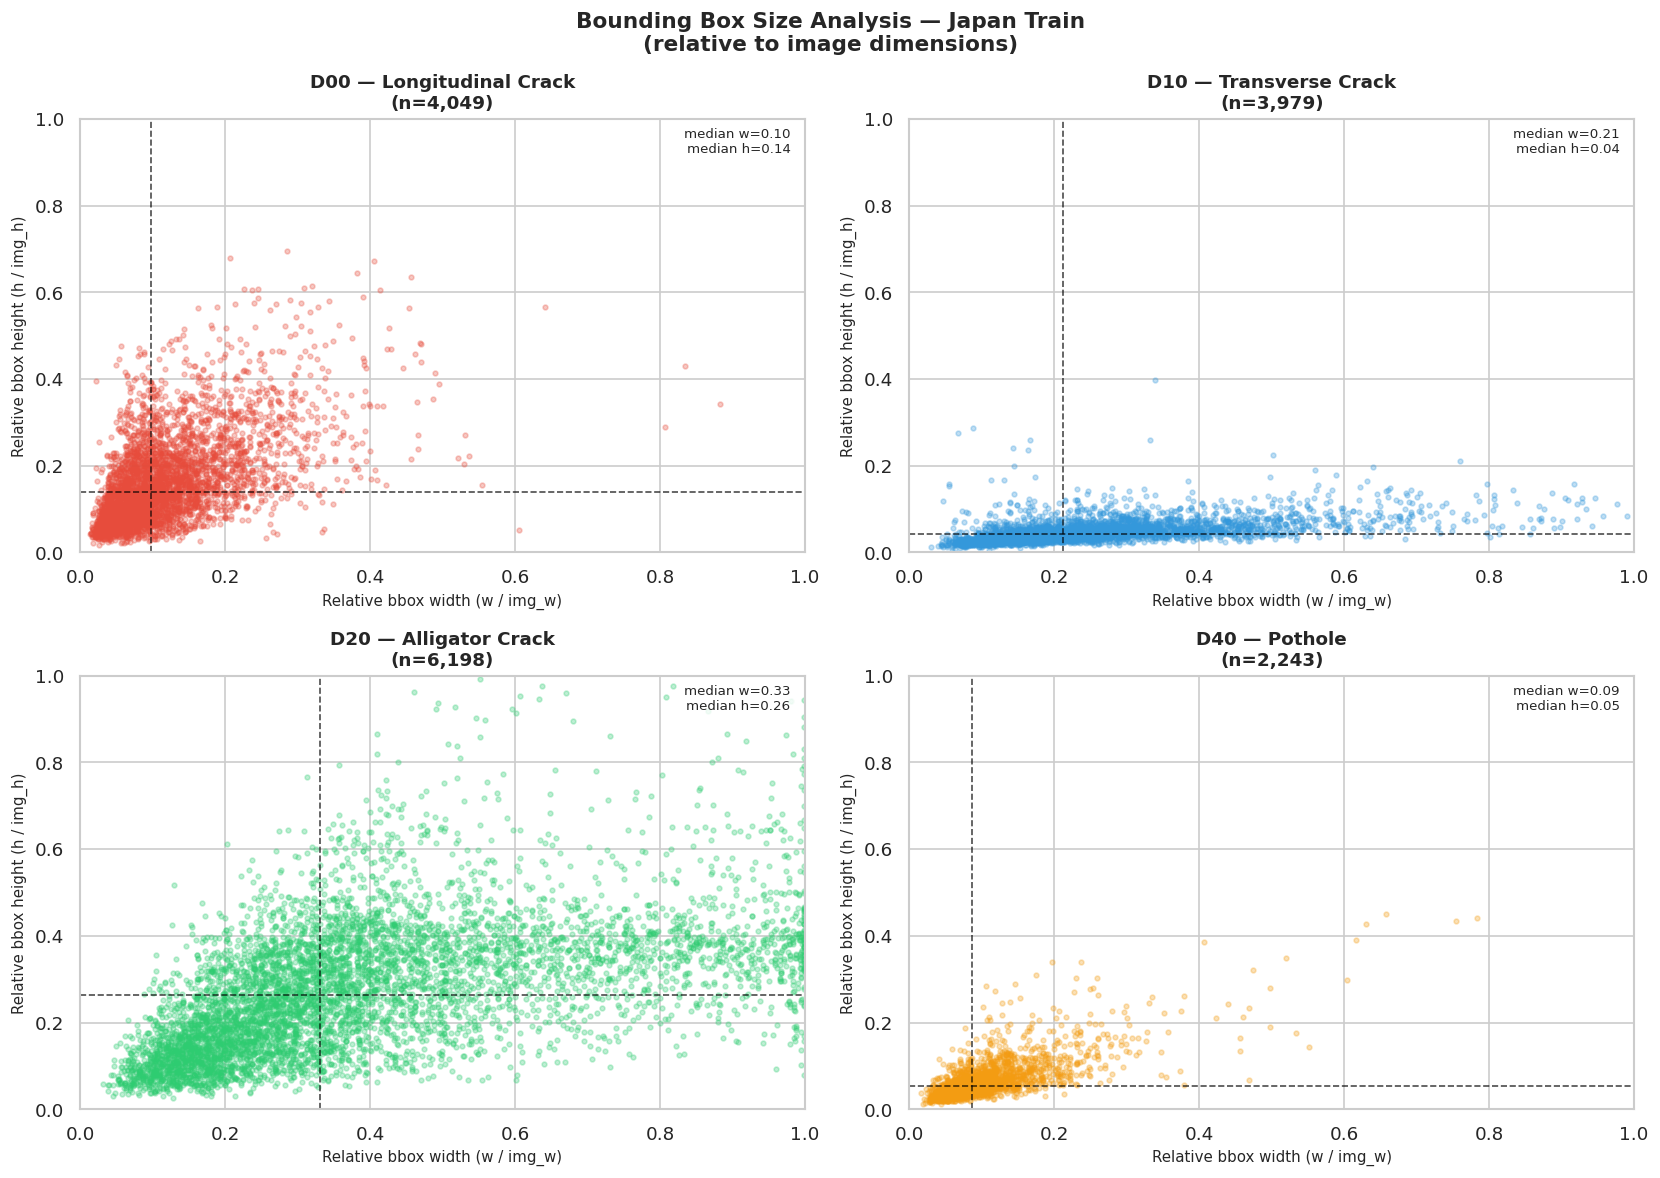

Saved: /mnt/c/Users/SN23341J001185/Documents/MyWork/ICT/ICTYear3_2/dl/DeepLearningPJ/outputs/figures/phase2_bbox_size_analysis.png

Takeaway: D00 wide/short, D10 tall/narrow, D20 large patch, D40 square/small
Many objects are small relative to image -> input size >= 640px needed in training


In [7]:
# Fig 3: Bounding box size analysis — Japan train
# Purpose: understand typical bbox dimensions per class -> informs input resolution choice

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for i, cls in enumerate(['D00', 'D10', 'D20', 'D40']):
    df_cls = df_japan_objs[df_japan_objs['label'] == cls]
    ax = axes[i]

    # Scatter: bbox width vs height (relative to image size)
    ax.scatter(df_cls['rel_w'], df_cls['rel_h'],
               alpha=0.3, s=8, color=CLASS_COLORS[cls], rasterized=True)
    ax.set_xlabel('Relative bbox width (w / img_w)', fontsize=9)
    ax.set_ylabel('Relative bbox height (h / img_h)', fontsize=9)
    ax.set_title(f'{cls} — {CLASS_NAMES[cls]}\n(n={len(df_cls):,})', fontsize=11, fontweight='bold')
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)

    # Annotate median
    med_w = df_cls['rel_w'].median()
    med_h = df_cls['rel_h'].median()
    ax.axvline(med_w, color='black', linestyle='--', linewidth=1, alpha=0.7)
    ax.axhline(med_h, color='black', linestyle='--', linewidth=1, alpha=0.7)
    ax.text(0.98, 0.98, f'median w={med_w:.2f}\nmedian h={med_h:.2f}',
            transform=ax.transAxes, ha='right', va='top', fontsize=8,
            bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

plt.suptitle('Bounding Box Size Analysis — Japan Train\n(relative to image dimensions)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
out_path = FIGURES_DIR / 'phase2_bbox_size_analysis.png'
plt.savefig(out_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved: {out_path}')
print('\nTakeaway: D00 wide/short, D10 tall/narrow, D20 large patch, D40 square/small')
print('Many objects are small relative to image -> input size >= 640px needed in training')

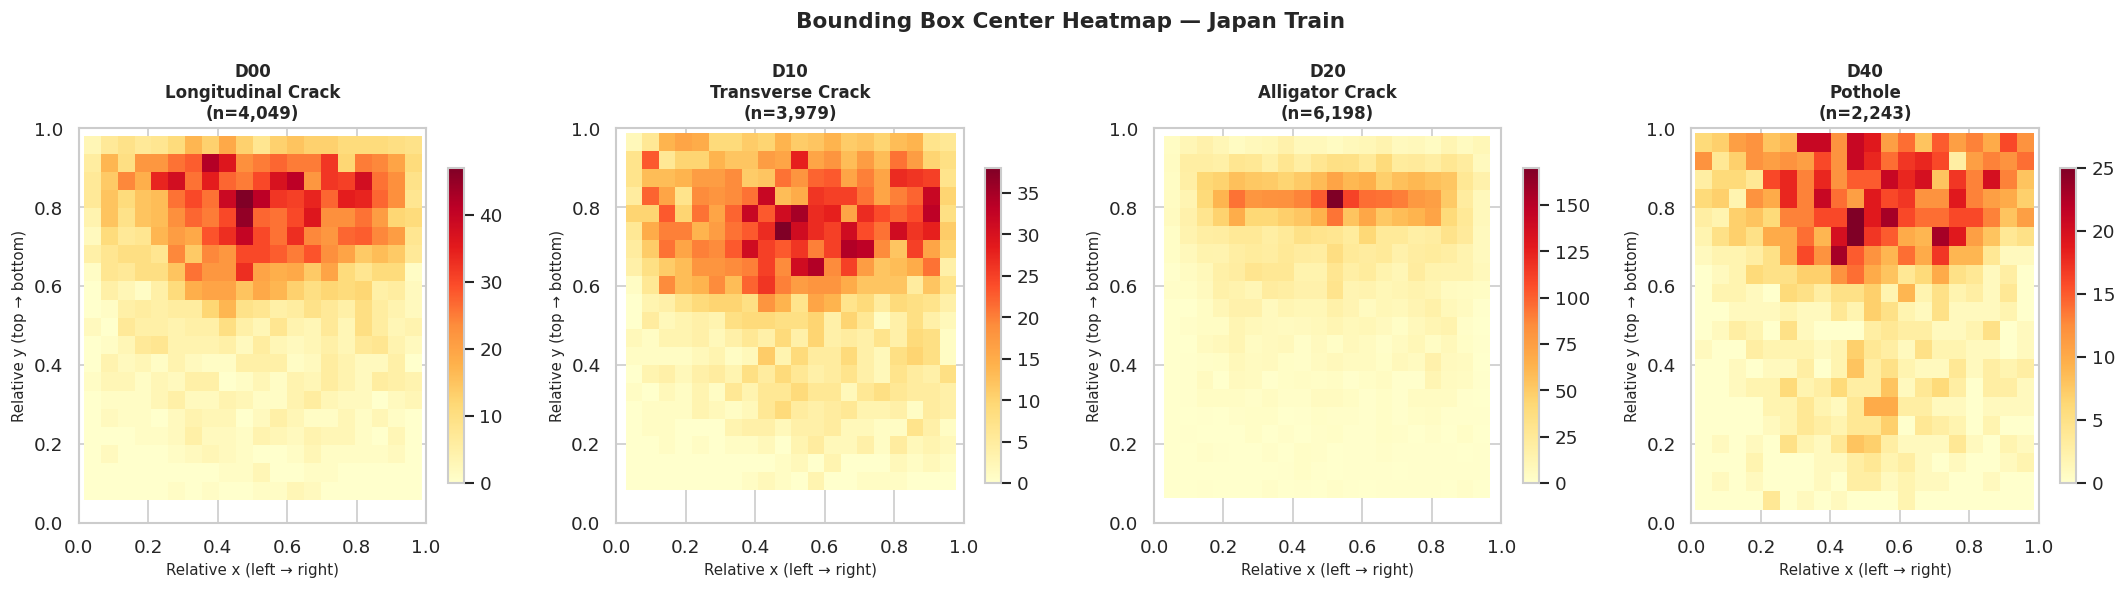

Saved: /mnt/c/Users/SN23341J001185/Documents/MyWork/ICT/ICTYear3_2/dl/DeepLearningPJ/outputs/figures/phase2_bbox_location_heatmap.png


In [8]:
# Fig 4: Bounding box center location heatmap — Japan train
# Purpose: check if damage tends to appear in specific image regions

fig, axes = plt.subplots(1, 4, figsize=(18, 5))

for i, cls in enumerate(['D00', 'D10', 'D20', 'D40']):
    df_cls = df_japan_objs[df_japan_objs['label'] == cls].copy()
    ax = axes[i]

    # Center coordinates (relative)
    cx = ((df_cls['xmin'] + df_cls['xmax']) / 2) / df_cls['img_w']
    cy = ((df_cls['ymin'] + df_cls['ymax']) / 2) / df_cls['img_h']

    h = ax.hist2d(cx.clip(0, 1), cy.clip(0, 1), bins=20, cmap='YlOrRd')
    plt.colorbar(h[3], ax=ax, shrink=0.8)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_xlabel('Relative x (left → right)', fontsize=9)
    ax.set_ylabel('Relative y (top → bottom)', fontsize=9)
    ax.set_title(f'{cls}\n{CLASS_NAMES[cls]}\n(n={len(df_cls):,})', fontsize=10, fontweight='bold')

plt.suptitle('Bounding Box Center Heatmap — Japan Train', fontsize=13, fontweight='bold')
plt.tight_layout()
out_path = FIGURES_DIR / 'phase2_bbox_location_heatmap.png'
plt.savefig(out_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved: {out_path}')

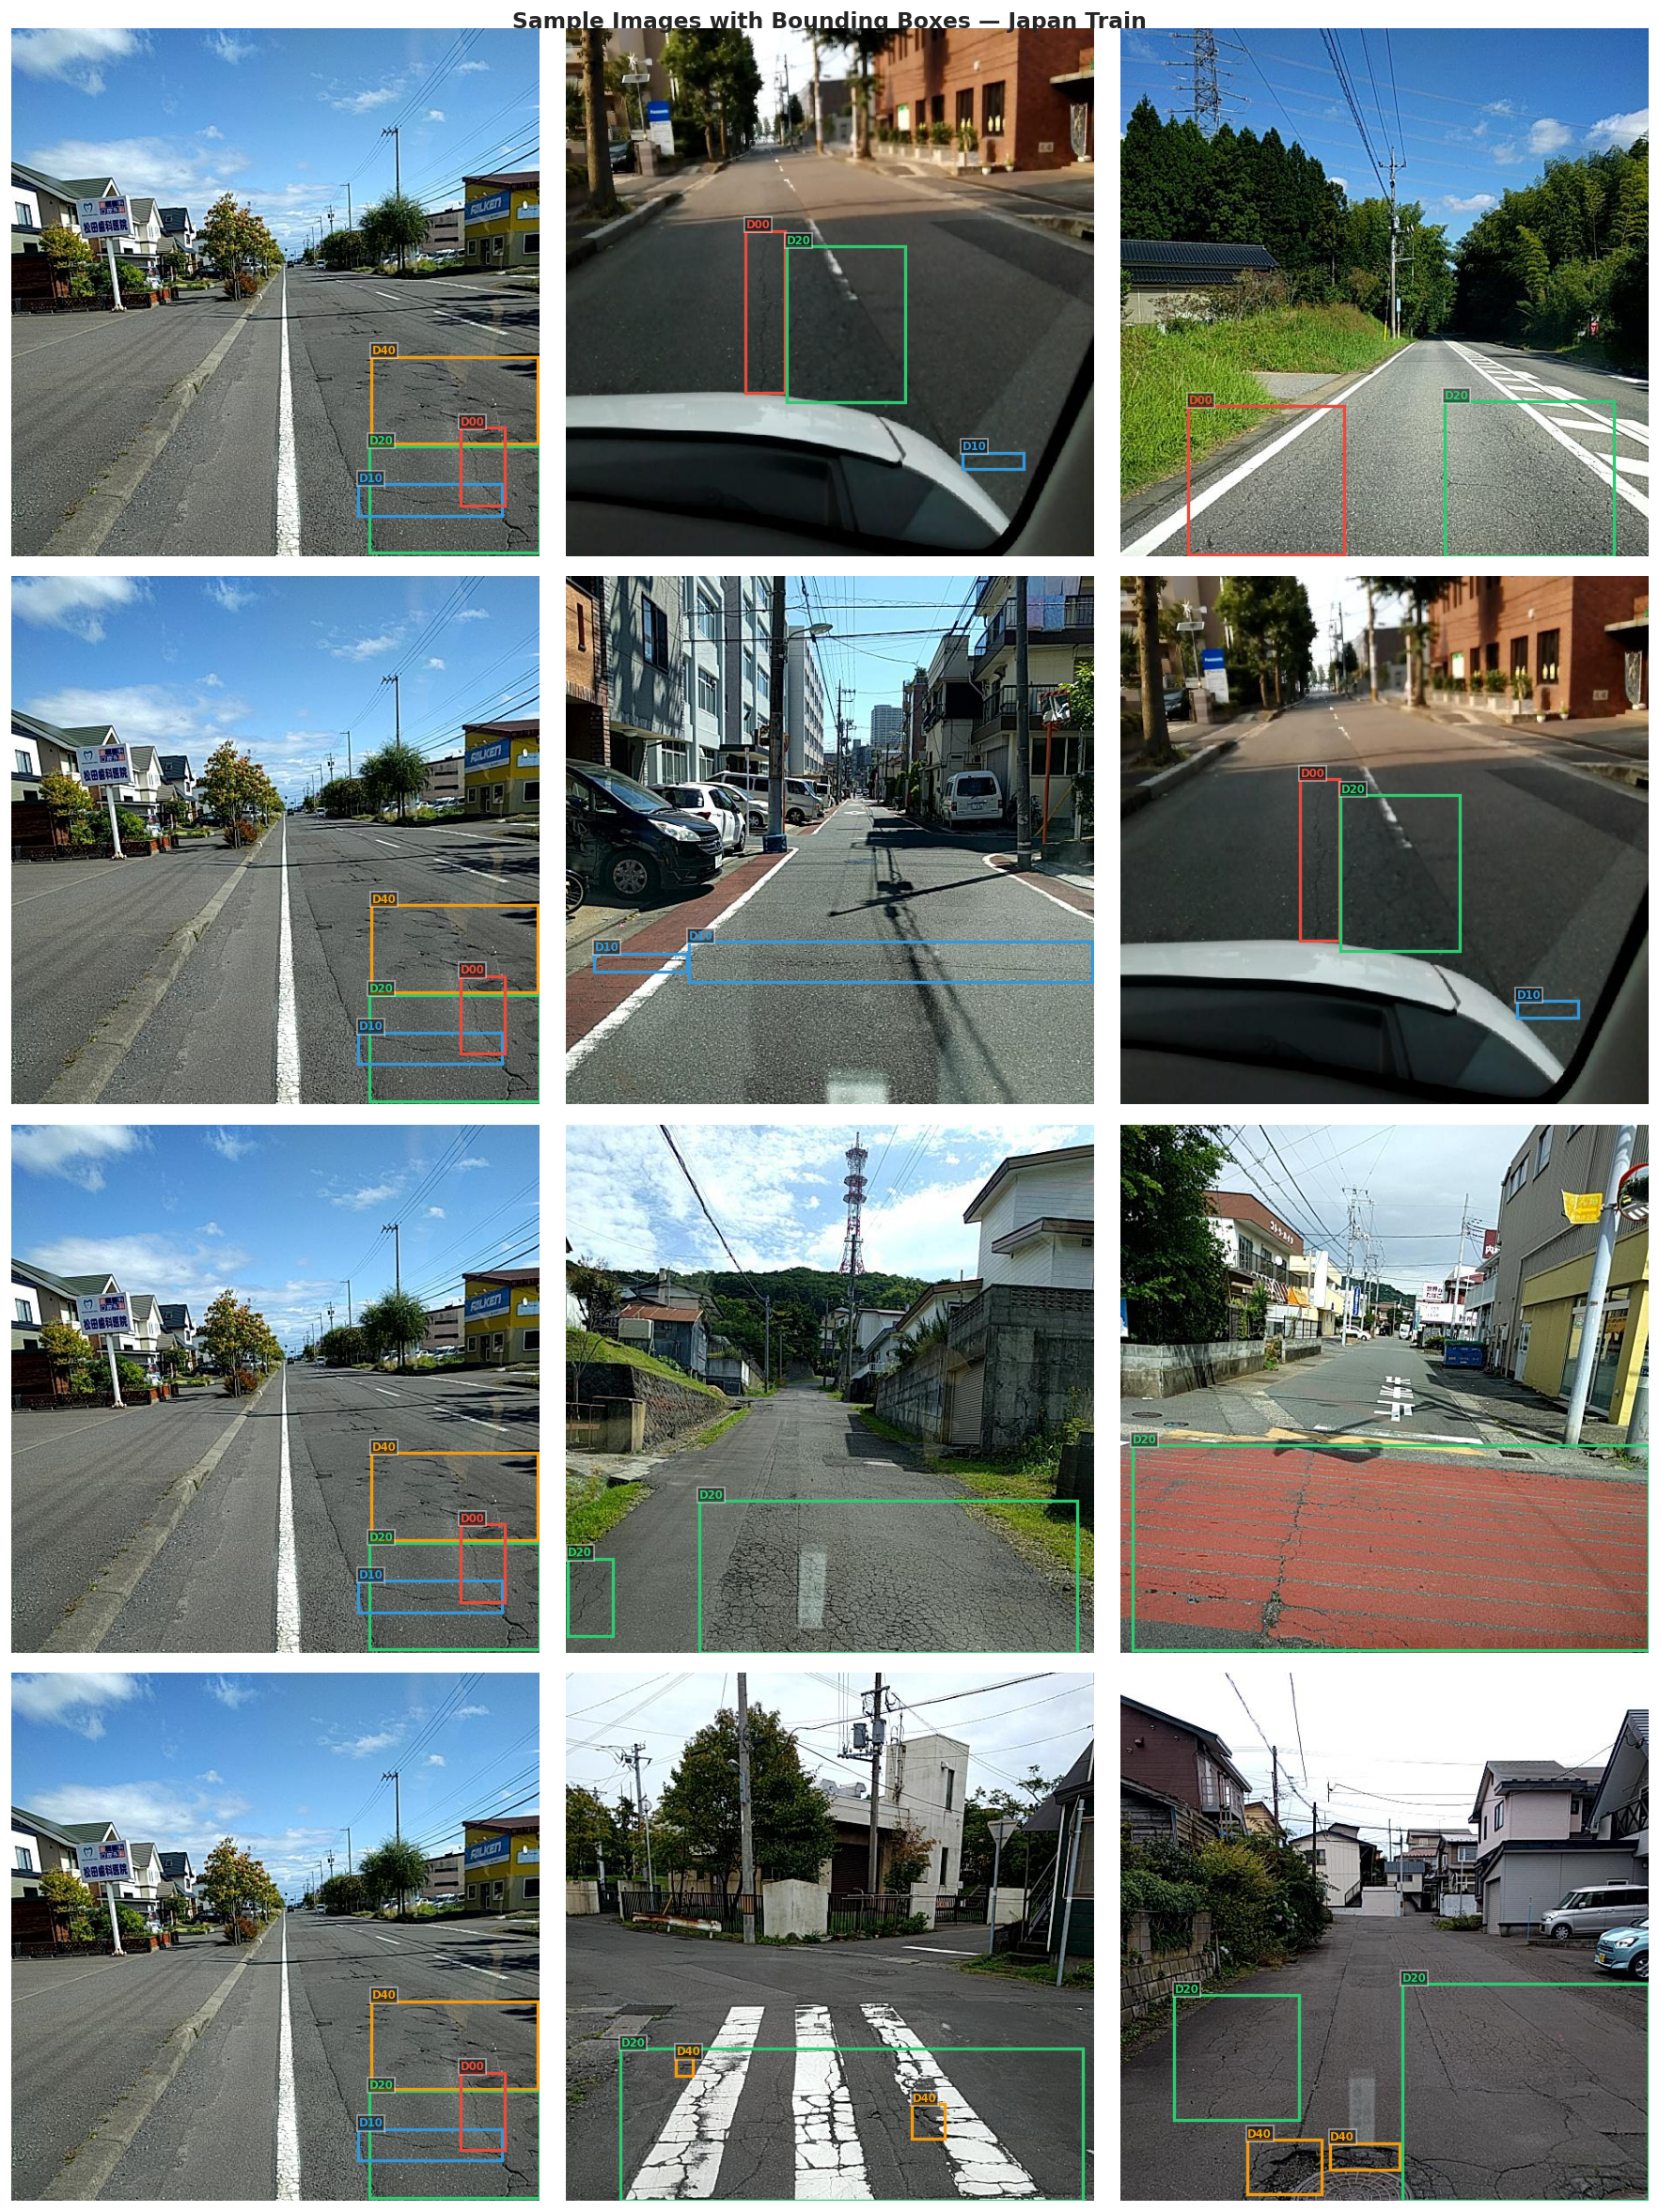

Saved: /mnt/c/Users/SN23341J001185/Documents/MyWork/ICT/ICTYear3_2/dl/DeepLearningPJ/outputs/figures/phase2_sample_images.png


In [9]:
# Fig 5: Sample images with bounding boxes — one per class
# Purpose: visual confirmation that labels are correct and images look as expected

IMG_DIR = Path(DATA_DIR) / 'Japan' / 'train' / 'images'

samples_per_class = 3
fig, axes = plt.subplots(4, samples_per_class, figsize=(15, 20))

for row_i, cls in enumerate(['D00', 'D10', 'D20', 'D40']):
    # Pick images that have at least one object of this class
    img_ids_with_cls = df_japan_objs[df_japan_objs['label'] == cls]['image_id'].unique()
    chosen = img_ids_with_cls[:samples_per_class]

    for col_i, img_id in enumerate(chosen):
        ax = axes[row_i][col_i]

        # Try common extensions
        img_path = None
        for ext in ['.jpg', '.jpeg', '.png']:
            candidate = IMG_DIR / (img_id + ext)
            if candidate.exists():
                img_path = candidate
                break

        if img_path is None:
            ax.set_visible(False)
            continue

        img = np.array(Image.open(img_path).convert('RGB'))
        ax.imshow(img)

        # Draw all bboxes in this image
        img_objs = df_japan_objs[df_japan_objs['image_id'] == img_id]
        for _, obj in img_objs.iterrows():
            rect = patches.Rectangle(
                (obj['xmin'], obj['ymin']), obj['bbox_w'], obj['bbox_h'],
                linewidth=2, edgecolor=CLASS_COLORS.get(obj['label'], 'white'),
                facecolor='none'
            )
            ax.add_patch(rect)
            ax.text(obj['xmin'], obj['ymin'] - 3, obj['label'],
                    color=CLASS_COLORS.get(obj['label'], 'white'),
                    fontsize=7, fontweight='bold',
                    bbox=dict(facecolor='black', alpha=0.5, pad=1))

        ax.axis('off')
        if col_i == 0:
            ax.set_ylabel(f'{cls}\n{CLASS_NAMES[cls]}', fontsize=10, fontweight='bold')

plt.suptitle('Sample Images with Bounding Boxes — Japan Train', fontsize=14, fontweight='bold')
plt.tight_layout()
out_path = FIGURES_DIR / 'phase2_sample_images.png'
plt.savefig(out_path, dpi=120, bbox_inches='tight')
plt.show()
print(f'Saved: {out_path}')

Japan               : 2,606 / 10,506 background (24.8%)
India               : 4,483 / 7,706 background (58.2%)
Norway              : 5,247 / 8,161 background (64.3%)
United_States       : 0 / 4,805 background (0.0%)
Czech               : 1,757 / 2,829 background (62.1%)


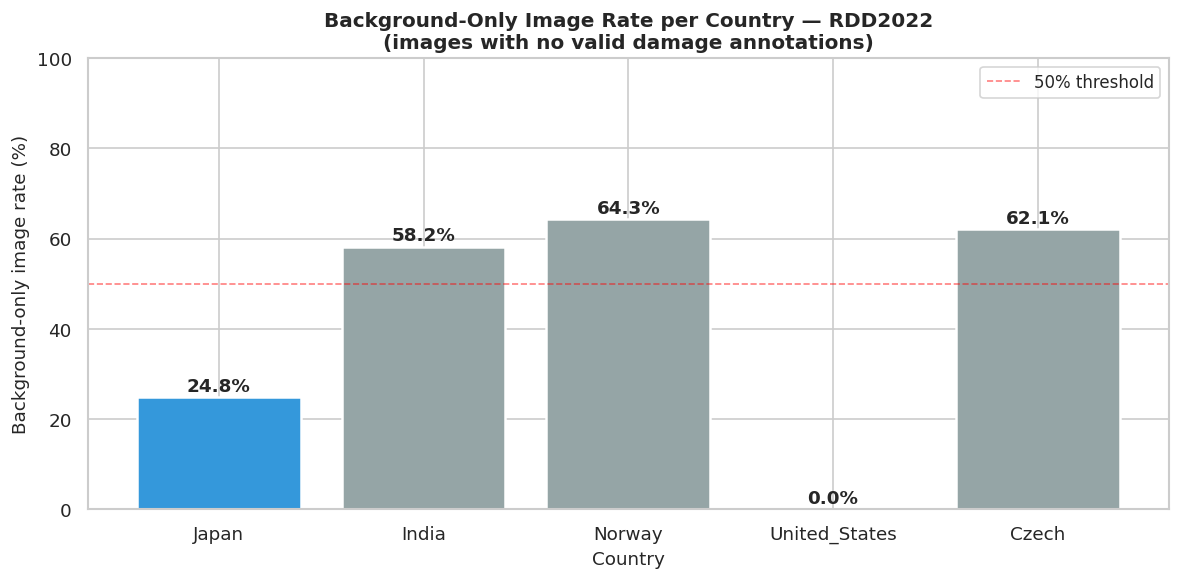

Saved: /mnt/c/Users/SN23341J001185/Documents/MyWork/ICT/ICTYear3_2/dl/DeepLearningPJ/outputs/figures/phase2_background_rate.png

Conclusion: keep background images in training (empty target list) to suppress false positives


In [10]:
# Fig 6: Background-only image rate per country
# Purpose: understand how many images have no damage labels -> affects dataloader design
# Decision: keep background images in training to reduce false positives

bg_rates = {}
for country in COUNTRIES_VALID:
    df = parse_all_annotations(country, DATA_DIR, split='train', filter_unknown=True)
    if df.empty:
        continue
    total_imgs = df['image_id'].nunique()
    bg_imgs = df[df['label'] == 'BACKGROUND']['image_id'].nunique()
    bg_rates[country] = bg_imgs / total_imgs * 100 if total_imgs > 0 else 0
    print(f'{country:<20}: {bg_imgs:,} / {total_imgs:,} background ({bg_rates[country]:.1f}%)')

fig, ax = plt.subplots(figsize=(10, 5))
countries = list(bg_rates.keys())
rates = list(bg_rates.values())
bar_colors = ['#3498DB' if c == 'Japan' else '#95A5A6' for c in countries]
bars = ax.bar(countries, rates, color=bar_colors, edgecolor='white', linewidth=1.5)
for bar, rate in zip(bars, rates):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.5,
            f'{rate:.1f}%', ha='center', va='bottom', fontsize=11, fontweight='bold')
ax.set_ylim(0, 100)
ax.set_ylabel('Background-only image rate (%)', fontsize=11)
ax.set_xlabel('Country', fontsize=11)
ax.set_title('Background-Only Image Rate per Country — RDD2022\n'
             '(images with no valid damage annotations)', fontsize=12, fontweight='bold')
ax.axhline(50, color='red', linestyle='--', linewidth=1, alpha=0.5, label='50% threshold')
ax.legend(fontsize=10)
plt.tight_layout()
out_path = FIGURES_DIR / 'phase2_background_rate.png'
plt.savefig(out_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved: {out_path}')
print('\nConclusion: keep background images in training (empty target list) to suppress false positives')